# Extension: SMA for feature selection

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mealpy import FloatVar, SMA, GWO, WOA, PSO
from mealpy.evolutionary_based import GA

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.datasets import fetch_openml
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier


import pickle
from pathlib import Path




In [2]:
X, y = fetch_openml('madelon',version=1, return_X_y=True, as_frame=False)
y = np.unique(y, return_inverse=True)[1]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y,random_state=42)

#500 features
D = X.shape[1]
#penalty weight on fraction of features used
LAMBDA = 0.01 
#fix folds so every candidate is scored the same way
cv = StratifiedKFold(3, shuffle=True,random_state=0)

THRESH = 0.9

def decode(sol):
    """Continuous vector in [0,1] -> boolean feature mask (feature on if > 0.5)"""
    mask = np.asarray(sol)>THRESH
    if not mask.any():
        mask[np.argmax(sol)]=True
    return mask

def fs_objective(sol):
    """CV error of KNN on selected features and penalty for using many features"""
    mask = decode(sol)
    clf = make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=5))
    err = 1 - cross_val_score(clf,X_train[:,mask],y_train, cv=cv).mean()
    return err + LAMBDA * mask.mean()

problem = {
    'bounds': FloatVar(lb=(0.,)*D, ub=(1.,)*D),
    'minmax':'min',
    'obj_func':fs_objective,
    'log_to':None
}

In [5]:
# Takes optimized solution and checks performance on test data.
def final_eval(sol):
    mask = decode(sol)
    clf = make_pipeline(StandardScaler(), SVC())
    clf.fit(X_train[:, mask],y_train)
    return clf.score(X_test[:,mask],y_test), int(mask.sum())

def random_search_fs(budget, pop_size, seed):
    """Random masks with varying subset sizes; same evaluation budget as the optimizers."""
    rng = np.random.default_rng(seed)
    best_fit, best_sol, history = np.inf, None, []
    for i in range(budget):
        density = rng.uniform(0.02, 0.5)                      # vary how many features are on
        sol = (rng.uniform(size=D) < density).astype(float)   # 500-long 0/1 vector
        fit = fs_objective(sol)
        if fit < best_fit:
            best_fit, best_sol = fit, sol
        if (i + 1) % pop_size == 0:
            history.append(best_fit)
    return best_sol, best_fit, history

def run_fs(problem, epoch=200, pop_size = 30, n_runs = 30):

    algorithms = {
        'SMA': lambda: SMA.OriginalSMA(epoch, pop_size=pop_size, p_t=0.03),
        'devSMA': lambda: SMA.DevSMA(epoch=epoch, pop_size=pop_size,p_t=0.03),
        'GA': lambda: GA.BaseGA(epoch=epoch, pop_size=pop_size)
    }

    names = list(algorithms) +['Random']
    keys = ['fit','cv_err','n_feat','test_acc','hist','mask']
    res = {n: {k: [] for k in keys} for n in names}

    def record(name, sol, fit, hist):
        mask = decode(sol)
        acc, k = final_eval(sol)
        r = res[name]
        r['fit'].append(fit)
        r['cv_err'].append(fit-LAMBDA*mask.mean())
        r['n_feat'].append(k)
        r['test_acc'].append(acc)
        r['hist'].append(hist)
        r['mask'].append(mask)

    for run in range(n_runs):
        for name, make_model in algorithms.items():
            model = make_model()
            g_best = model.solve(problem, seed=run)
            record(name, g_best.solution, g_best.target.fitness,
                   model.history.list_global_best_fit)
        sol, fit, hist = random_search_fs(epoch * pop_size, pop_size, seed= run +1000)
        record('Random',sol, fit, hist)
        print(f"finished run {run+1}/{n_runs}")

        # save results after each run
        with open("fs_results.pkl", "wb") as f:
            pickle.dump(res, f)

    rows = []
    for n in names:
        r = res[n]
        rows.append({
            'Algorithm':n,
            'Fitness (mean)': np.mean(r['fit']),
            'Fitness (std)': np.std(r['fit'],ddof=1) if n_runs>1 else np.nan,
            'CV error': np.mean(r['cv_err']),
            '# features': np.mean(r['n_feat']),
            'Test acc': np.mean(r['test_acc'])
        })

    return pd.DataFrame(rows).set_index('Algorithm'),res




all_mask = np.ones(D)
acc_all, _ = final_eval(all_mask)
print(f"All {D} features -> SVM test acc {acc_all:.4f}")

import time; t0=time.time()
table, res = run_fs(problem,n_runs=2)
print(f"{time.time()-t0:.0f}s for 2 runs")
print(table.to_string(float_format = lambda x: f"{x:.4f}"))

All 500 features -> SVM test acc 0.5833
finished run 1/2
finished run 2/2
591s for 2 runs
           Fitness (mean)  Fitness (std)  CV error  # features  Test acc
Algorithm                                                               
SMA                0.3855         0.0012    0.3854      2.0000    0.6571
devSMA             0.3800         0.0082    0.3799      2.0000    0.6519
GA                 0.0919         0.0000    0.0918      8.5000    0.8532
Random             0.4104         0.0168    0.4102     12.5000    0.6391


In [7]:
# rank on the training set only, keep the top 50
rf = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=0).fit(X_train, y_train)
keep = np.argsort(rf.feature_importances_)[::-1][:50]

X_train_full, X_test_full = X_train, X_test            # keep the originals
X_train, X_test = X_train[:, keep], X_test[:, keep]
D = X_train.shape[1]                                    # now 50

problem = {'bounds': FloatVar(lb=(0.,) * D, ub=(1.,) * D),
           'minmax': 'min', 'obj_func': fs_objective, 'log_to': None}

epoch, pop_size = 100, 30
algorithms = {
    'SMA':    lambda: SMA.OriginalSMA(epoch=epoch, pop_size=pop_size, p_t=0.03),
    'devSMA': lambda: SMA.DevSMA(epoch=epoch, pop_size=pop_size, p_t=0.03),
    'GA':     lambda: GA.BaseGA(epoch=epoch, pop_size=pop_size),
}

table, res = run_fs(problem, epoch=epoch, pop_size=pop_size, n_runs=30)
print(table.to_string(float_format=lambda x: f"{x:.4f}"))

finished run 1/30
finished run 2/30
finished run 3/30
finished run 4/30
finished run 5/30
finished run 6/30
finished run 7/30
finished run 8/30
finished run 9/30
finished run 10/30
finished run 11/30
finished run 12/30
finished run 13/30
finished run 14/30
finished run 15/30
finished run 16/30
finished run 17/30
finished run 18/30
finished run 19/30
finished run 20/30
finished run 21/30
finished run 22/30
finished run 23/30
finished run 24/30
finished run 25/30
finished run 26/30
finished run 27/30
finished run 28/30
finished run 29/30
finished run 30/30
           Fitness (mean)  Fitness (std)  CV error  # features  Test acc
Algorithm                                                               
SMA                0.1776         0.0399    0.1766      4.5667    0.7943
devSMA             0.2017         0.0353    0.2006      5.5000    0.7800
GA                 0.0939         0.0038    0.0924      7.7000    0.8489
Random             0.1502         0.0224    0.1485      8.6667    0.8206


In [8]:
from scipy.stats import mannwhitneyu

pairs = [("SMA", "devSMA"), ("SMA", "GA"), ("SMA", "Random"), ("GA", "Random")]
for metric in ["fit", "test_acc"]:
    print(metric)
    for a, b in pairs:
        _, p = mannwhitneyu(res[a][metric], res[b][metric], alternative="two-sided")
        print(f"  {a} vs {b}: median {np.median(res[a][metric]):.4f} vs "
              f"{np.median(res[b][metric]):.4f}, p = {min(p * len(pairs), 1):.4f} (Bonferroni)")

fit
  SMA vs devSMA: median 0.1934 vs 0.2013, p = 0.1457 (Bonferroni)
  SMA vs GA: median 0.1934 vs 0.0941, p = 0.0000 (Bonferroni)
  SMA vs Random: median 0.1934 vs 0.1504, p = 0.0095 (Bonferroni)
  GA vs Random: median 0.0941 vs 0.1504, p = 0.0000 (Bonferroni)
test_acc
  SMA vs devSMA: median 0.7923 vs 0.7763, p = 0.4962 (Bonferroni)
  SMA vs GA: median 0.7923 vs 0.8481, p = 0.0000 (Bonferroni)
  SMA vs Random: median 0.7923 vs 0.8218, p = 0.0100 (Bonferroni)
  GA vs Random: median 0.8481 vs 0.8218, p = 0.0000 (Bonferroni)


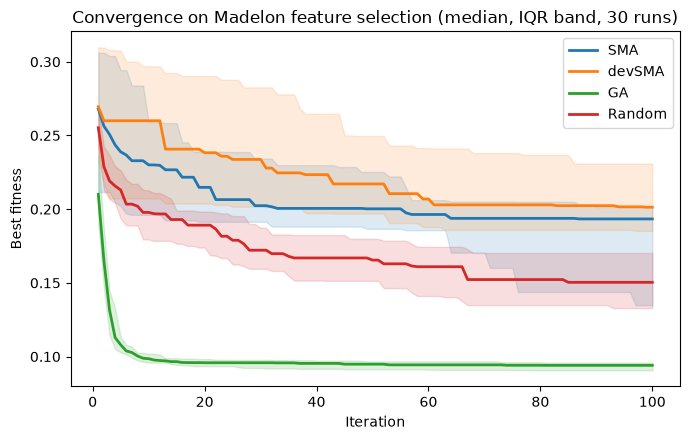

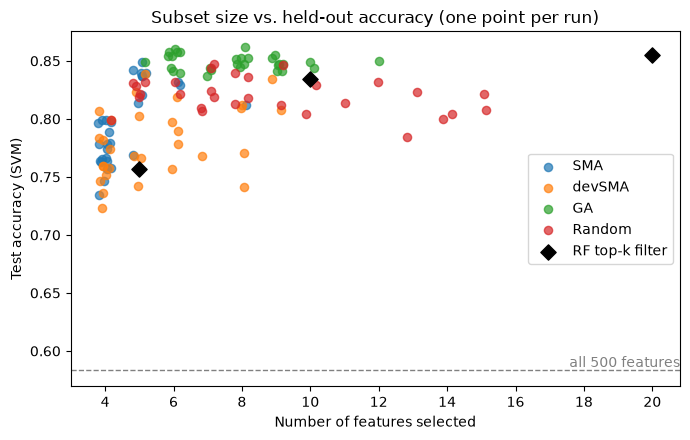

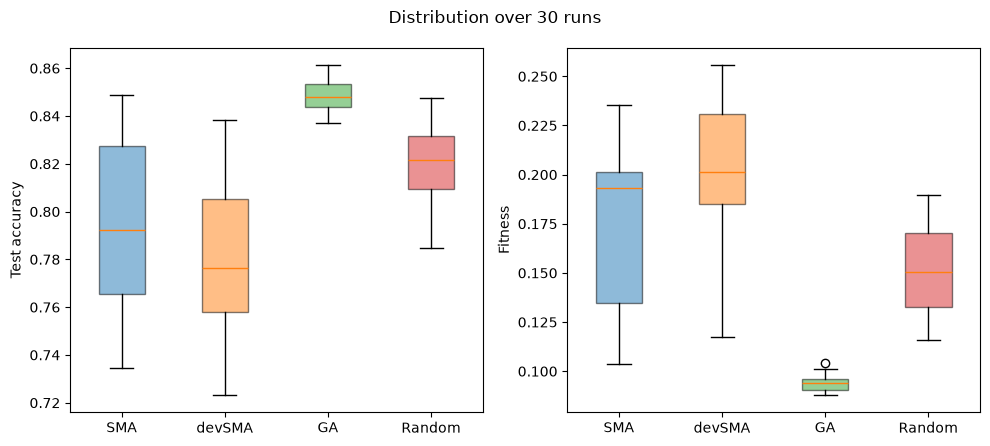

In [17]:
with open("fs_results.pkl", "rb") as f:     # skip these two lines if `res` is already in memory
    res = pickle.load(f)

fig_dir = Path("results/figures"); fig_dir.mkdir(parents=True, exist_ok=True)
names = list(res)
colors = dict(zip(names, plt.cm.tab10.colors))

# Reference points from your random forest diagnostic (training-set ranking)
rf_ref = {5: 0.7564, 10: 0.8346, 20: 0.8551}
ALL_FEATURES_ACC = 0.5833

# ---------- Figure 1: convergence curves ----------
fig, ax = plt.subplots(figsize=(7, 4.5))
for n in names:
    H = res[n]["hist"]
    L = min(len(h) for h in H)                       # guard against unequal lengths
    H = np.array([h[:L] for h in H])                 # shape (runs, epochs)
    med = np.median(H, axis=0)
    lo, hi = np.percentile(H, [25, 75], axis=0)
    x = np.arange(1, L + 1)
    ax.plot(x, med, label=n, color=colors[n], lw=2)
    ax.fill_between(x, lo, hi, color=colors[n], alpha=0.15)
ax.set(xlabel="Iteration", ylabel="Best fitness",
       title="Convergence on Madelon feature selection (median, IQR band, 30 runs)")
ax.legend()
fig.tight_layout()
fig.savefig(fig_dir / "convergence.png", dpi=200)

# ---------- Figure 2: features selected vs. test accuracy ----------
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(7, 4.5))
for n in names:
    k = np.array(res[n]["n_feat"], dtype=float) + rng.uniform(-0.2, 0.2, len(res[n]["n_feat"]))  # jitter
    ax.scatter(k, res[n]["test_acc"], label=n, color=colors[n], alpha=0.7, s=35)
ax.scatter(list(rf_ref), list(rf_ref.values()), marker="D", color="black",
           s=60, label="RF top-k filter", zorder=5)
ax.axhline(ALL_FEATURES_ACC, color="gray", ls="--", lw=1)
ax.text(ax.get_xlim()[1], ALL_FEATURES_ACC, " all 500 features", va="bottom", ha="right", color="gray")
ax.set(xlabel="Number of features selected", ylabel="Test accuracy (SVM)",
       title="Subset size vs. held-out accuracy (one point per run)")
ax.legend()
fig.tight_layout()
fig.savefig(fig_dir / "features_vs_accuracy.png", dpi=200)

# ---------- Figure 3: distribution of test accuracy and fitness ----------
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, key, label in [(axes[0], "test_acc", "Test accuracy"),
                       (axes[1], "fit", "Fitness")]:
    bp = ax.boxplot([res[n][key] for n in names], tick_labels=names, patch_artist=True)
    for patch, n in zip(bp["boxes"], names):
        patch.set_facecolor(colors[n]); patch.set_alpha(0.5)
    ax.set_ylabel(label)
fig.suptitle("Distribution over 30 runs")
fig.tight_layout()
fig.savefig(fig_dir / "distributions.png", dpi=200)

plt.show()

In [16]:
for n in ["SMA", "GA", "Random"]:
    h = np.array([x[:min(len(y) for y in res[n]["hist"])] for x in res[n]["hist"]])
    print(n, "first iteration:", np.median(h[:, 0]).round(3), "-> last:", np.median(h[:, -1]).round(3))

SMA first iteration: 0.268 -> last: 0.193
GA first iteration: 0.21 -> last: 0.094
Random first iteration: 0.255 -> last: 0.15
